In [20]:
# Import libraries
from pathlib import Path
import time
import warnings

warnings.filterwarnings("ignore")

import pandas as pd
import nglview as nv
from pypdb.clients.pdb.pdb_client import get_pdb_file

# import openbabel
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors
from plip.structure.preparation import PDBComplex
from plip.exchange.report import BindingSiteReport

from opencadd.structure.core import Structure

In [21]:
def get_structure(pdb_id):
    # download the PDB file content.
    pdb_file_content = get_pdb_file(pdb_id)
    # create an nglview structure object from the content
    structure = nv.TextStructure(pdb_file_content, ext="pdb")
    return structure


def get_pdb_nglviewer(pdb_id, default_representation=True, gui=False):
    structure = get_structure(pdb_id)
    # set structure viewer
    nglviewer = nv.show_file(structure, default_representation=default_representation, gui=gui)
    return nglviewer

In [22]:
import urllib.request
import biotite.structure.io as bsio
import biotite.structure as struc

# 1. Download the PDB file directly using standard Python libraries
url = "https://files.rcsb.org/download/3POZ.pdb"
urllib.request.urlretrieve(url, "3POZ.pdb")
print("Downloaded 3POZ.pdb successfully!")

# 2. Load it using Biotite
source_array = bsio.load_structure("3POZ.pdb", extra_fields=["charge"])

# 3. Verification
print(f"Successfully loaded structure! Total atoms: {len(source_array)}")

Downloaded 3POZ.pdb successfully!
Successfully loaded structure! Total atoms: 2536


In [23]:
import nglview as nv

# Load the local PDB file directly
view = nv.show_file("3POZ.pdb")
view

NGLWidget()

In [24]:
ngl_viewer = get_pdb_nglviewer(pdb_id)
# add the ligands
ngl_viewer.add_representation(repr_type="ball+stick", selection="hetero and not water")
# center view on binding site
ngl_viewer.center("ligand")
ngl_viewer

Sending GET request to https://files.rcsb.org/download/3poz.pdb to fetch 3poz's pdb file as a string.


NGLWidget()

In [27]:
# render a static image
ngl_viewer.render_image(trim=True, factor=2);

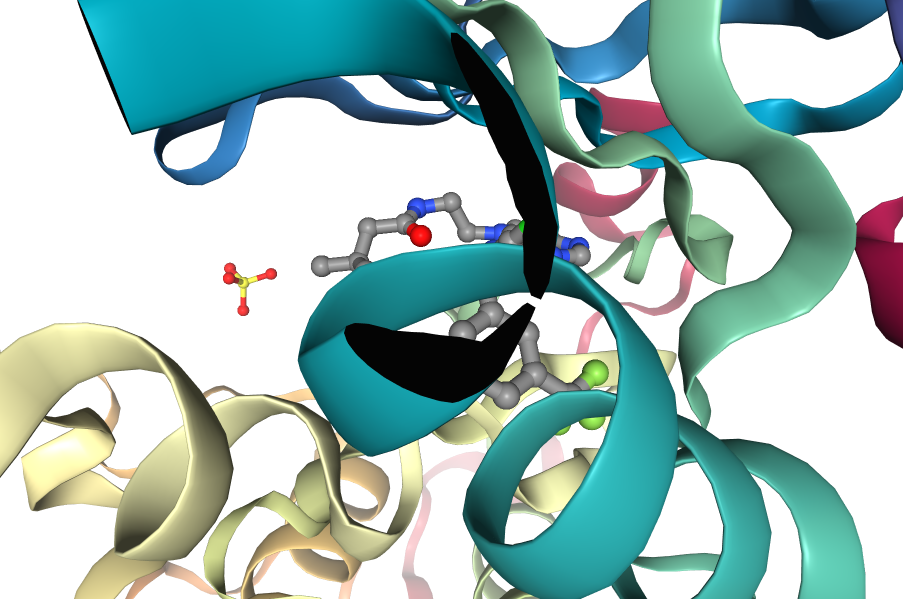

In [28]:
ngl_viewer._display_image()

In [29]:
def retrieve_plip_interactions(pdb_file):
    """
    Retrieves the interactions from PLIP.

    Parameters
    ----------
    pdb_file :
        The PDB file of the complex.

    Returns
    -------
    dict :
        A dictionary of the binding sites and the interactions.
    """
    protlig = PDBComplex()
    protlig.load_pdb(pdb_file)  # load the pdb file
    for ligand in protlig.ligands:
        protlig.characterize_complex(ligand)  # find ligands and analyze interactions
    sites = {}
    # loop over binding sites
    for key, site in sorted(protlig.interaction_sets.items()):
        binding_site = BindingSiteReport(site)  # collect data about interactions
        # tuples of *_features and *_info will be converted to pandas DataFrame
        keys = (
            "hydrophobic",
            "hbond",
            "waterbridge",
            "saltbridge",
            "pistacking",
            "pication",
            "halogen",
            "metal",
        )
        # interactions is a dictionary which contains relevant information for each
        # of the possible interactions: hydrophobic, hbond, etc. in the considered
        # binding site. Each interaction contains a list with
        # 1. the features of that interaction, e.g. for hydrophobic:
        # ('RESNR', 'RESTYPE', ..., 'LIGCOO', 'PROTCOO')
        # 2. information for each of these features, e.g. for hydrophobic
        # (residue nb, residue type,..., ligand atom 3D coord., protein atom 3D coord.)
        interactions = {
            k: [getattr(binding_site, k + "_features")] + getattr(binding_site, k + "_info")
            for k in keys
        }
        sites[key] = interactions
    return sites

In [31]:
interactions_by_site = retrieve_plip_interactions("3POZ.pdb")

In [ ]:
print(
    f"Number of binding sites detected in 3POZ : "
    f"{len(interactions_by_site)}\n"
    f"with {interactions_by_site.keys()}"
)
# residue ID: chain: sequence #

Number of binding sites detected in 3POZ : 4
with dict_keys(['03P:A:1023', 'SO4:A:1', 'SO4:A:2', 'SO4:A:3'])


In [33]:
index_of_selected_site = 0
selected_site = list(interactions_by_site.keys())[index_of_selected_site]
print(selected_site)

03P:A:1023


In [34]:
def create_df_from_binding_site(selected_site_interactions, interaction_type="hbond"):
    """
    Creates a data frame from a binding site and interaction type.

    Parameters
    ----------
    selected_site_interactions : dict
        Precaluclated interactions from PLIP for the selected site
    interaction_type : str
        The interaction type of interest (default set to hydrogen bond).

    Returns
    -------
    pd.DataFrame :
        DataFrame with information retrieved from PLIP.
    """

    # check if interaction type is valid:
    valid_types = [
        "hydrophobic",
        "hbond",
        "waterbridge",
        "saltbridge",
        "pistacking",
        "pication",
        "halogen",
        "metal",
    ]

    if interaction_type not in valid_types:
        print("!!! Wrong interaction type specified. Hbond is chosen by default!!!\n")
        interaction_type = "hbond"

    df = pd.DataFrame.from_records(
        # data is stored AFTER the column names
        selected_site_interactions[interaction_type][1:],
        # column names are always the first element
        columns=selected_site_interactions[interaction_type][0],
    )
    return df

In [35]:
create_df_from_binding_site(interactions_by_site[selected_site], interaction_type="hydrophobic")

,RESNR,RESTYPE,RESCHAIN,RESNR_LIG,RESTYPE_LIG,RESCHAIN_LIG,DIST,LIGCARBONIDX,PROTCARBONIDX,LIGCOO,PROTCOO
0,745,LYS,A,1023,03P,A,3.91,2399,320,"(18.317, 32.25, 10.052)","(20.469, 34.989, 8.267)"
1,788,LEU,A,1023,03P,A,3.66,2384,595,"(18.404, 30.743, 6.486)","(18.317, 33.573, 4.169)"
2,790,THR,A,1023,03P,A,3.80,2398,611,"(16.476, 34.203, 10.862)","(12.875, 33.449, 9.914)"
3,854,THR,A,1023,03P,A,3.82,2383,1138,"(18.135, 32.543, 11.422)","(17.798, 28.992, 12.797)"
4,858,LEU,A,1023,03P,A,3.93,2384,1167,"(18.404, 30.743, 6.486)","(22.084, 30.736, 5.093)"


In [36]:
create_df_from_binding_site(interactions_by_site[selected_site], interaction_type="hbond")

,RESNR,RESTYPE,RESCHAIN,RESNR_LIG,RESTYPE_LIG,RESCHAIN_LIG,SIDECHAIN,DIST_H-A,DIST_D-A,DON_ANGLE,PROTISDON,DONORIDX,DONORTYPE,ACCEPTORIDX,ACCEPTORTYPE,LIGCOO,PROTCOO
0,793,MET,A,1023,03P,A,False,2.01,2.96,163.57,True,629,Nam,2405,Nar,"(13.371, 34.064, 15.005)","(10.667, 33.654, 16.145)"


In [37]:
create_df_from_binding_site(interactions_by_site[selected_site], interaction_type="halogen")

,RESNR,RESTYPE,RESCHAIN,RESNR_LIG,RESTYPE_LIG,RESCHAIN_LIG,SIDECHAIN,DIST,DON_ANGLE,ACC_ANGLE,DON_IDX,DONORTYPE,ACC_IDX,ACCEPTORTYPE,LIGCOO,PROTCOO
0,766,MET,A,1023,03P,A,False,3.60,167.05,118.86,2390,F,431,O2,"(14.283, 28.118, 6.395)","(12.164, 26.835, 3.777)"
1,788,LEU,A,1023,03P,A,False,3.23,159.67,108.02,2397,Cl,592,O2,"(15.676, 34.766, 8.319)","(14.792, 37.053, 6.216)"
2,790,THR,A,1023,03P,A,True,3.47,171.27,103.84,2389,F,610,O3,"(13.867, 29.356, 8.056)","(11.467, 31.629, 9.124)"


In [38]:
color_map = {
    "hydrophobic": [0.90, 0.10, 0.29],
    "hbond": [0.26, 0.83, 0.96],
    "waterbridge": [1.00, 0.88, 0.10],
    "saltbridge": [0.67, 1.00, 0.76],
    "pistacking": [0.75, 0.94, 0.27],
    "pication": [0.27, 0.60, 0.56],
    "halogen": [0.94, 0.20, 0.90],
    "metal": [0.90, 0.75, 1.00],
}

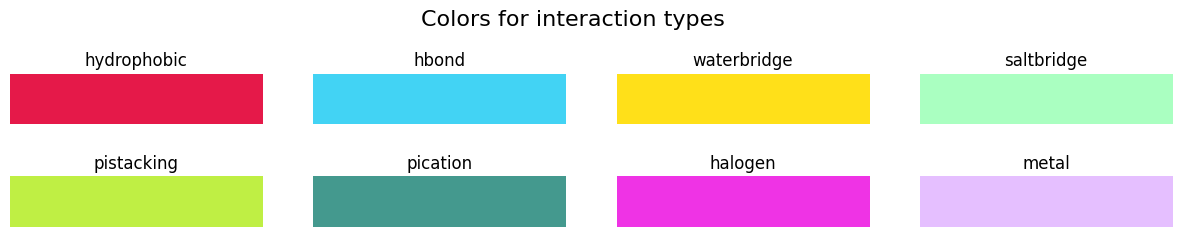

In [39]:
fig, axs = plt.subplots(nrows=2, ncols=4, figsize=(15, 2))
plt.subplots_adjust(hspace=1)
fig.suptitle("Colors for interaction types", size=16, y=1.2)

for ax, (interaction, color) in zip(fig.axes, color_map.items()):
    ax.imshow(np.zeros((1, 5)), cmap=colors.ListedColormap(color_map[interaction]))
    ax.set_title(interaction, loc="center")
    ax.set_axis_off()
plt.show()

In [48]:
def show_interactions_3d(
    pdb_id, selected_site_interactions, highlight_interaction_colors=color_map
):
    """
    3D visualization of protein-ligand interactions.

    Parameters
    ----------
    pdb_id : str
        The pdb ID of interest.
    selected_site_interactions : dict
        Precaluclated interactions from PLIP for the selected site
    highlight_interaction_colors : dict
        The colors used to highlight the different interaction types.

    Returns
    -------
    NGL viewer with explicit interactions given by PLIP.
    """

    # Create NGLviewer
    viewer = nv.NGLWidget(height="600px", default=True, gui=True)
    # Add protein
    prot_component = viewer.add_pdbid(pdb_id)
    # Add the ligands
    viewer.add_representation(repr_type="ball+stick", selection="hetero and not water")

    interacting_residues = []
    for interaction_type, interaction_list in selected_site_interactions.items():
        color = highlight_interaction_colors[interaction_type]
        if len(interaction_list) == 1:
            continue
        df_interactions = pd.DataFrame.from_records(
            interaction_list[1:], columns=interaction_list[0]
        )
        for _, interaction in df_interactions.iterrows():
            name = interaction_type
            # add cylinder between ligand and protein coordinate
            viewer.shape.add_cylinder(
                interaction["LIGCOO"],
                interaction["PROTCOO"],
                color,
                [0.1],
                name,
            )
            interacting_residues.append(interaction["RESNR"])
    # Display interacting residues
    res_sele = " or ".join([f"({r} and not _H)" for r in interacting_residues])
    res_sele_nc = " or ".join([f"({r} and ((_O) or (_N) or (_S)))" for r in interacting_residues])
    prot_component.add_ball_and_stick(sele=res_sele, colorScheme="chainindex", aspectRatio=1.5)
    prot_component.add_ball_and_stick(sele=res_sele_nc, colorScheme="element", aspectRatio=1.5)
    # Center on ligand
    viewer.center("ligand")
    return viewer

In [49]:
viewer_3d = show_interactions_3d(pdb_id, interactions_by_site[selected_site])

In [51]:
viewer_3d.render_image(trim=True, factor=2, transparent=True)
viewer_3d._display_image()
viewer_3d

NGLWidget()